### Part 1: Data Preparation and Exploration

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
df = pd.read_csv("D:\\Data science\\Assignments\\Questions\\Timeseries\\Timeseries\\exchange_rate.csv")
df.head()

,date,Ex_rate
0,01-01-1990 00:00,0.7855
1,02-01-1990 00:00,0.7818
2,03-01-1990 00:00,0.7867
3,04-01-1990 00:00,0.7860
4,05-01-1990 00:00,0.7849


<Axes: >

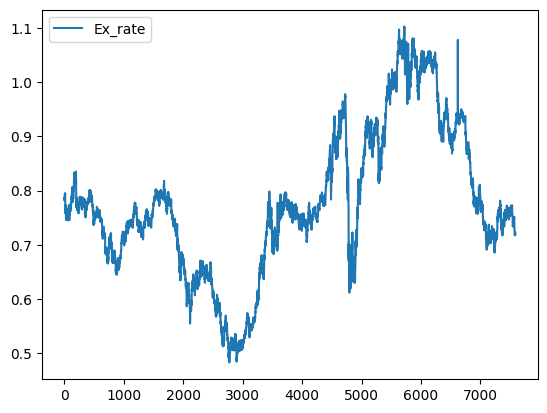

In [77]:
df.plot(y='Ex_rate')

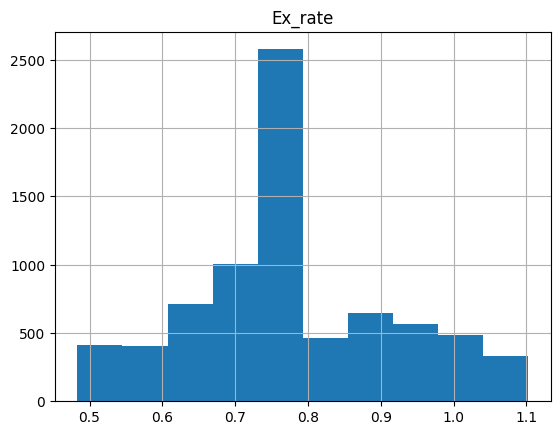

In [78]:
df.hist()
plt.show()

In [79]:
df.isnull().sum()

date       0
Ex_rate    0
dtype: int64

hence no missing values to handle  
also no preprocessing required 

<Figure size 4000x1000 with 0 Axes>

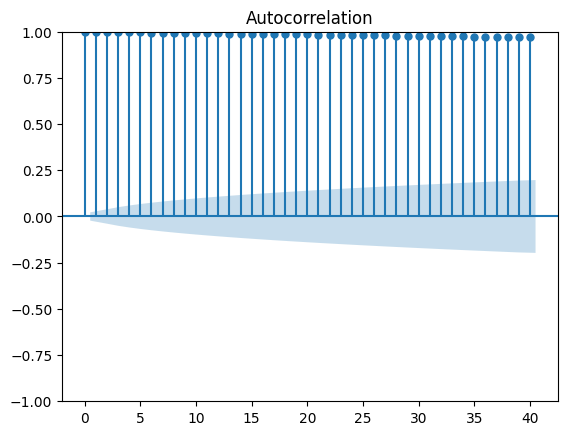

In [80]:
from statsmodels.graphics.tsaplots import plot_acf
plt.figure(figsize = (40,10))
plot_acf(df['Ex_rate'], lags=40)
plt.show()

### Part 2: Model Building - ARIMA

In [81]:
from statsmodels.tsa.arima.model import ARIMA

In [137]:
#                        p,q,d
model = ARIMA(df['Ex_rate'], order=(5,1,1))
model_fitted = model.fit()
model_fitted.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                Ex_rate   No. Observations:                 7588
Model:                 ARIMA(5, 1, 1)   Log Likelihood               28055.688
Date:                Wed, 24 Sep 2025   AIC                         -56097.375
Time:                        12:09:36   BIC                         -56048.836
Sample:                             0   HQIC                        -56080.717
                               - 7588                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0661      0.661     -0.100      0.920      -1.362       1.230
ar.L2          0.0061      0.086      0.071      0.944      -0.163       0.175
ar.L3         -0.0167      0.007     -2.337      0.019      -0.031      -0.003
ar.L4          0.0003      0.014      0.018      0.985      -0.027       0.028
ar.L5          0.0112      0.009      1.212      0.225      -0.007       0.029
ma.L1         -0.0653      0.661     -0.099      0.921      -1.361       1.230
sigma2      3.594e-05   1.01e-07    354.458      0.000    3.57e-05    3.61e-05
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):           2865000.68
Prob(Q):                              0.99   Prob(JB):                         0.00
Heteroskedasticity (H):               2.97   Skew:                             0.25
Prob(H) (two-sided):                  0.00   Kurtosis:                        98.20
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [138]:
model_fitted.resid

0       0.785500
1      -0.003700
2       0.004414
3      -0.000058
4      -0.001240
          ...   
7583   -0.000294
7584    0.003312
7585    0.001779
7586   -0.002197
7587   -0.000241
Length: 7588, dtype: float64

In [139]:
rmse = np.sqrt(np.mean((model_fitted.resid)**2))
print("RMSE:",np.round(rmse,3))

RMSE: 0.011


we are getting mest rmse of 0.011 at 1 so 1 is the best perameter

Out-of-sample forecast:
7588    0.720802
7589    0.720881
7590    0.720890
7591    0.720864
7592    0.720865
          ...   
7733    0.720865
7734    0.720865
7735    0.720865
7736    0.720865
7737    0.720865
Name: predicted_mean, Length: 150, dtype: float64


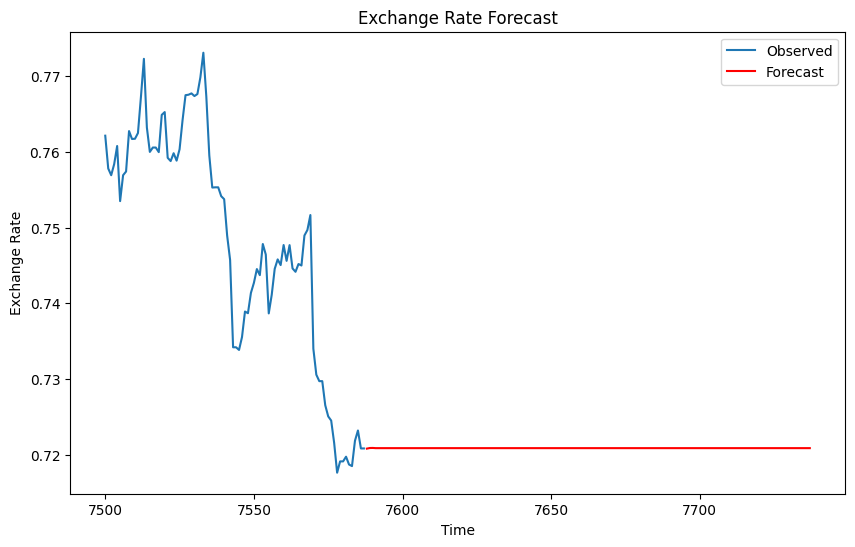

In [140]:
# Perform out-of-sample forecasting
n_forecast = 150  # Number of steps to forecast
forecast = model_fitted.forecast(steps=n_forecast)

# Print the forecast
print("Out-of-sample forecast:")
print(forecast)

# Plot the forecast
X = df['Ex_rate'].iloc[7500:]
plt.figure(figsize=(10, 6))
plt.plot(X, label='Observed')
plt.plot(forecast , label='Forecast', color='red')
plt.title('Exchange Rate Forecast')
plt.xlabel('Time')
plt.ylabel('Exchange Rate')
plt.legend()
plt.show()

### Part 3: Model Building - Exponential Smoothing

In [86]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing

#### SMS

In [109]:
df

,date,Ex_rate
0,01-01-1990 00:00,0.785500
1,02-01-1990 00:00,0.781800
2,03-01-1990 00:00,0.786700
3,04-01-1990 00:00,0.786000
4,05-01-1990 00:00,0.784900
...,...,...
7583,06-10-2010 00:00,0.718494
7584,07-10-2010 00:00,0.721839
7585,08-10-2010 00:00,0.723197
7586,09-10-2010 00:00,0.720825


<Axes: >

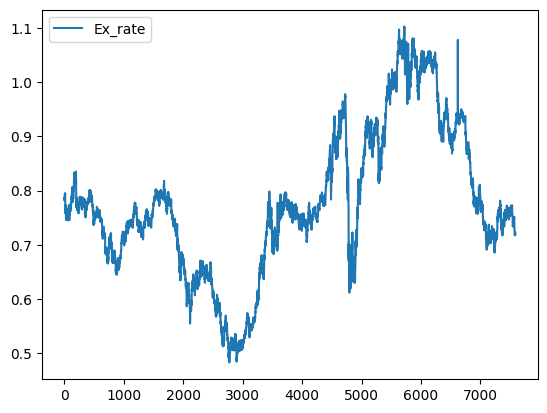

In [110]:
df.plot()

In [111]:
model = SimpleExpSmoothing(df['Ex_rate'])
# model_fitted = model.fit(smoothing_level=0.2, optimized=False) #---> to give alfa manually
model_fitted = model.fit(optimized=True) #--->auto chooses the alfa value/smooth value to reduse mse or rmse


In [112]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

0.005996587930402878

In [113]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 5)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0       0.785500
1       0.785500
2       0.782282
3       0.786125
4       0.786016
          ...   
7583    0.718825
7584    0.718537
7585    0.721409
7586    0.722964
7587    0.721103
Length: 7588, dtype: float64
Forecasted values: 7588    0.720861
7589    0.720861
7590    0.720861
7591    0.720861
7592    0.720861
dtype: float64


In [114]:
X = df['Ex_rate'].iloc[7500:]
X_forecaste = pd.DataFrame(model_fitted.fittedvalues)
Y = X_forecaste[0].iloc[7500:]

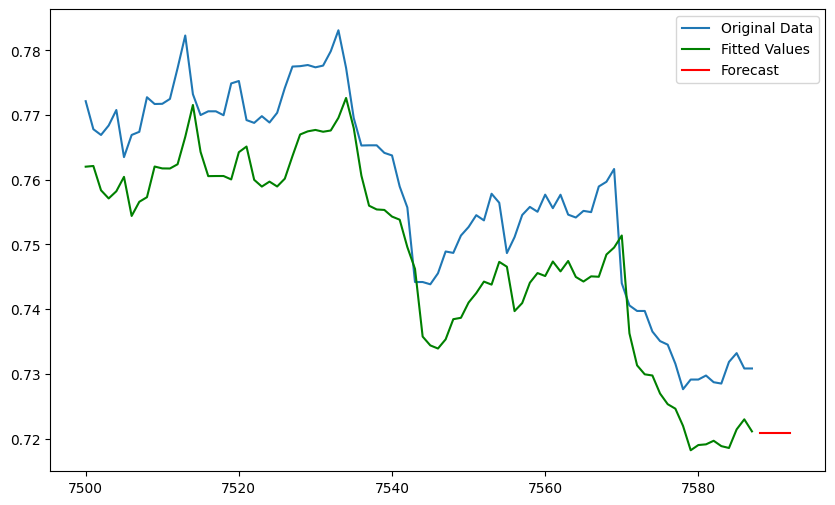

In [117]:
plt.figure(figsize=(10,6))
plt.plot(X + 0.01, label = 'Original Data')
plt.plot(Y, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+5), forecast, label='Forecast', color='red')
plt.legend()
plt.show()

good with past values but no change in future forcaste values

#### holts linear

In [118]:
model = ExponentialSmoothing(df['Ex_rate'], trend = 'add', seasonal=None)
# model_fitted = model.fit(smoothing_level=0.8, smoothing_slope=0.2, optimized=False)
model_fitted = model.fit(optimized=True)

In [119]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

0.005996578239395609

In [120]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 5)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0       0.785101
1       0.785440
2       0.782265
3       0.786114
4       0.786006
          ...   
7583    0.718815
7584    0.718527
7585    0.721399
7586    0.722955
7587    0.721094
Length: 7588, dtype: float64
Forecasted values: 7588    0.720852
7589    0.720843
7590    0.720835
7591    0.720826
7592    0.720818
dtype: float64


In [121]:
X = df['Ex_rate'].iloc[7500:]
X_forecaste = pd.DataFrame(model_fitted.fittedvalues)
Y = X_forecaste[0].iloc[7500:]

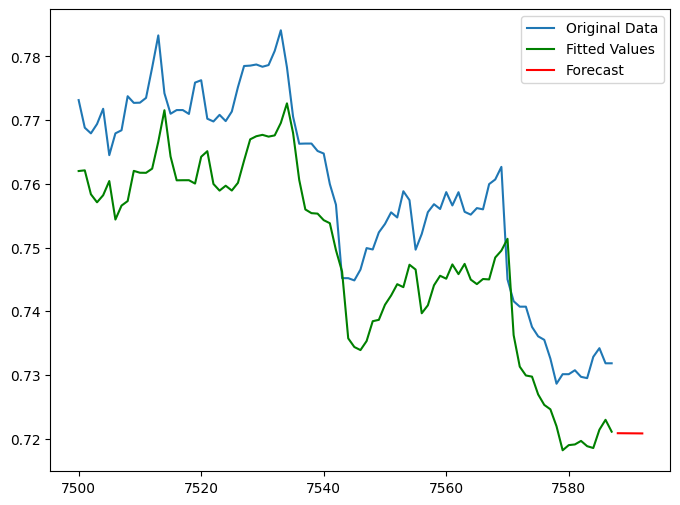

In [122]:
plt.figure(figsize=(8,6))
plt.plot(X+0.011, label = 'Original Data')
plt.plot(Y, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+5), forecast, label='Forecast', color='red')
plt.legend()
plt.show()

not adjusting the future values  
so not good but rmse is better than SMS

#### holt seasonal

In [131]:
model = ExponentialSmoothing(df['Ex_rate'], trend = 'add', seasonal='add', seasonal_periods=6)
# model_fitted_Holt = model.fit(smoothing_level=0.8, smoothing_slope=0.2, optimized=False)
model_fitted_Holt = model.fit(optimized=True)

In [132]:
rmse = np.sqrt(np.mean(model_fitted_Holt.resid**2))
display(rmse)

0.006029196693770605

In [142]:
# next 10 periods ==> h = 10
forecast = model_fitted_Holt.forecast(steps = 10)
print("Fitted value: ", model_fitted_Holt.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0       0.786105
1       0.786163
2       0.781930
3       0.785793
4       0.785730
          ...   
7583    0.718241
7584    0.718675
7585    0.721635
7586    0.723928
7587    0.720868
Length: 7588, dtype: float64
Forecasted values: 7588    0.720318
7589    0.719818
7590    0.720063
7591    0.720191
7592    0.721038
7593    0.720774
7594    0.720263
7595    0.719762
7596    0.720007
7597    0.720135
dtype: float64


In [150]:
X = df['Ex_rate'].iloc[7500:]
X_forecaste = pd.DataFrame(model_fitted_Holt.fittedvalues)
Y = X_forecaste[0].iloc[7500:]

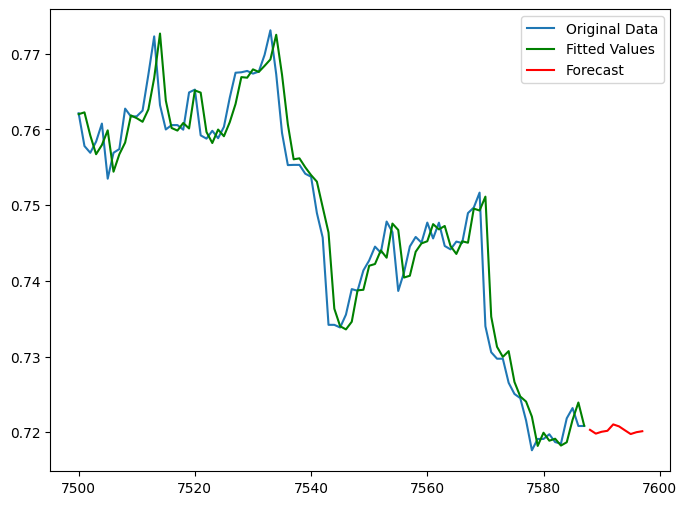

In [152]:
plt.figure(figsize=(8,6))
plt.plot(X, label = 'Original Data')
plt.plot(Y, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+10), forecast, label='Forecast', color='red')
plt.legend()
plt.show()

we can see that holts seasonal has gives us the best results with slight changes in forecaste  
but rmse is minutly low that is of 0.01  
so holts seasonal is the best for this data set  
comparision is also been visulized

### Part 4: Evaluation and Comparison

In [141]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

arima_predictions = model_fitted.fittedvalues
holt_predictions = model_fitted_Holt.fittedvalues


actual_values = df['Ex_rate']

# Calculate metrics for ARIMA
mae_arima = mean_absolute_error(actual_values, arima_predictions)
rmse_arima = np.sqrt(mean_squared_error(actual_values, arima_predictions))
# MAPE calculation: Avoid division by zero
mape_arima = np.mean(np.abs((actual_values - arima_predictions) / actual_values)) * 100


# Calculate metrics for Holt's optimized model
mae_holt = mean_absolute_error(actual_values, holt_predictions)
rmse_holt = np.sqrt(mean_squared_error(actual_values, holt_predictions))
# MAPE calculation: Avoid division by zero
mape_holt = np.mean(np.abs((actual_values - holt_predictions) / actual_values)) * 100

print("ARIMA Model Evaluation:")
print(f"  MAE: {mae_arima:.3f}")
print(f"  RMSE: {rmse_arima:.3f}")
print(f"  MAPE: {mape_arima:.3f}%")

print("\nHolt's Optimized Model Evaluation:")
print(f"  MAE: {mae_holt:.3f}")
print(f"  RMSE: {rmse_holt:.3f}")
print(f"  MAPE: {mape_holt:.3f}%")

ARIMA Model Evaluation:
  MAE: 0.004
  RMSE: 0.011
  MAPE: 0.495%

Holt's Optimized Model Evaluation:
  MAE: 0.004
  RMSE: 0.006
  MAPE: 0.487%


#### Model Performance Comparison

From the calculated metrics:

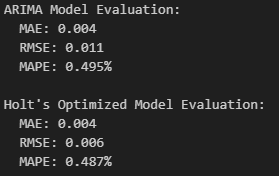

In this case, the Holt's Optimized Model shows significantly lower values for all three error metrics (MAE, RMSE, and MAPE) compared to the ARIMA Model. This suggests that, for this specific dataset and on the training data, the Holt's Optimized Model provides a better fit and likely more accurate predictions.

#### Advantages and Limitations

**ARIMA Model:**

*   **Advantages:**
    *   Can model a wide range of time series patterns, including trends, seasonality, and autoregressive/moving average components.
    *   Provides a structured approach to time series forecasting based on statistical properties.
    *   The `statsmodels` implementation offers detailed summary statistics for model interpretation.
*   **Limitations:**
    *   Requires the time series to be stationary (or be made stationary through differencing).
    *   Selecting the optimal (p, d, q) parameters can be challenging and time-consuming (as seen with the grid search).
    *   Can be sensitive to outliers.
    *   The out-of-sample forecast in our case appeared as a straight line, suggesting it might not capture complex future patterns well.

**Holt's Linear Exponential Smoothing Model:**

*   **Advantages:**
    *   Relatively simple to understand and implement.
    *   Effective for time series.
    *   The optimized fitting can automatically find good smoothing parameters.
    *   Provides a smoother forecast compared to models that might be more sensitive to noise.
*   **Limitations:**
    *   Assumes a linear trend. It may not perform well if the trend is non-linear or changes over time.
    *   Does handle seasonality. seasonality is present, a Holt-Winters model is more appropriate.
    *   The forecast tends to flatten out over longer horizons, assuming the trend continues linearly.

#### Conclusion

Based on the lower error metrics on the training data, the **Holt's Optimized Model** appears to be the better choice for this dataset among the two models we evaluated. Its simplicity and effectiveness in capturing the trend seem well-suited to the observed data characteristics. The ARIMA model, while more flexible, did not perform as well in this instance, possibly due to the chosen parameters or the nature of the time series.
